<a href="https://colab.research.google.com/github/cdiegor/Metaheuristicas/blob/main/CVRP_2026_2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

<a href="https://colab.research.google.com/github/cdiegor/Metaheuristicas/blob/main/AG_CVRP_BRKGA.ipynb" target="_parent">
<img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/>
</a>


# Algoritmos Genéticos para o Problema de Roteamento de Veículos Capacitado

Neste notebook vamos estudar **Algoritmos Genéticos (GA)** utilizando o
**Problema de Roteamento de Veículos Capacitado (CVRP)**.

O material continua a sequência do notebook anterior:

$$
\text{PCV}
\rightarrow
\text{PRV / giant tour}
\rightarrow
\text{Split}
\rightarrow
\boxed{\text{CVRP + Algoritmos Genéticos}}.
$$

A principal ideia será separar duas responsabilidades:

$$
\boxed{\text{algoritmo evolutivo: procura uma boa permutação}}
$$

e

$$
\boxed{\text{Split capacitado: transforma a permutação em rotas viáveis}}.
$$

Faremos duas implementações:

1. um **GA implementado passo a passo**, para estudar população, seleção,
   crossover, mutação e elitismo;
2. um **BRKGA (Biased Random-Key Genetic Algorithm)** utilizando a biblioteca
   `pymoo`, no qual a parte evolutiva é fornecida pela biblioteca e nós
   implementamos essencialmente a **decodificação**.


## Objetivos

Ao final do notebook, esperamos compreender:

- como representar soluções de um problema combinatório em um GA;
- por que crossovers para permutações precisam preservar todos os clientes;
- o papel da seleção, elitismo, mutação e diversidade;
- como utilizar um **decoder exato** dentro de uma metaheurística;
- como funciona a representação por **random keys**;
- a diferença entre implementar um GA "no braço" e utilizar uma infraestrutura
  genérica como o `pymoo`;
- como comparar duas metaheurísticas estocásticas de maneira experimentalmente
  razoável.


# 1. Problema de Roteamento de Veículos Capacitado

Temos um conjunto de clientes

$$
V=\{1,\ldots,n\}
$$

e um depósito representado pelo vértice \(0\).

Cada cliente \(i\) possui uma demanda

$$
q_i>0,
$$

e cada veículo possui capacidade \(Q\).

Uma rota

$$
0\rightarrow i_1\rightarrow i_2\rightarrow\cdots\rightarrow i_k\rightarrow0
$$

é viável quando

$$
\sum_{j=1}^{k}q_{i_j}\leq Q.
$$

Dispomos de no máximo \(R\) veículos e queremos atender todos os clientes
exatamente uma vez minimizando a distância total percorrida.

Neste notebook consideraremos coordenadas euclidianas, de modo que

$$
c_{ij}=\|p_i-p_j\|_2.
$$


In [1]:
import copy
import itertools
import math
import random
import statistics
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd


In [2]:
class CVRP:
    def __init__(self):
        self.clientes = []      # coordenadas; clientes[0] é o depósito
        self.demandas = []      # demandas[0] = 0
        self.veiculos = 0       # número máximo de veículos
        self.capacidade = 0
        self.rotas = []         # cada rota guarda índices de clientes, sem o depósito
        self.dist = None        # matriz de distâncias

    @property
    def n_clientes(self):
        return len(self.clientes) - 1

    def construir_matriz_distancias(self):
        n = len(self.clientes)
        self.dist = np.zeros((n, n), dtype=float)

        for i in range(n):
            for j in range(i + 1, n):
                d = math.dist(self.clientes[i], self.clientes[j])
                self.dist[i, j] = d
                self.dist[j, i] = d

    def custo_rota(self, rota):
        """Custo de 0 -> rota -> 0."""
        if len(rota) == 0:
            return 0.0

        custo = self.dist[0, rota[0]]

        for i in range(len(rota) - 1):
            custo += self.dist[rota[i], rota[i + 1]]

        custo += self.dist[rota[-1], 0]
        return float(custo)

    def carga_rota(self, rota):
        return sum(self.demandas[i] for i in rota)

    def custo(self):
        return sum(self.custo_rota(r) for r in self.rotas)

    def viavel(self):
        visitados = [i for rota in self.rotas for i in rota]

        clientes_ok = sorted(visitados) == list(range(1, self.n_clientes + 1))
        capacidade_ok = all(
            self.carga_rota(r) <= self.capacidade
            for r in self.rotas
        )
        frota_ok = len(self.rotas) <= self.veiculos

        return clientes_ok and capacidade_ok and frota_ok

    def __repr__(self):
        return (
            f"Clientes={self.n_clientes} | "
            f"Veículos≤{self.veiculos} | "
            f"Capacidade={self.capacidade} | "
            f"Rotas={len(self.rotas)} | "
            f"Custo={self.custo():.2f}"
        )


### Construindo instâncias fictícias

Para fins didáticos, geraremos clientes aleatoriamente em uma região retangular.

As demandas serão inteiras entre 1 e 9. Quando a capacidade não for informada,
utilizaremos uma capacidade aproximadamente 20% superior à demanda média por
veículo. Isso tende a produzir instâncias em que a capacidade é relevante, sem
tornar a maior parte das permutações inviável.


In [3]:
def gerar_cvrp(
    n,
    r,
    capacidade=None,
    largura=1000,
    altura=700,
    fator_folga=1.20,
    rseed=233
):
    rng = random.Random(rseed)

    I = CVRP()
    I.veiculos = r

    I.clientes = [
        (rng.randrange(largura), rng.randrange(altura))
        for _ in range(n + 1)
    ]

    # Depósito no centro.
    I.clientes[0] = (largura // 2, altura // 2)

    I.demandas = [0] + [
        rng.randint(1, 9)
        for _ in range(n)
    ]

    if capacidade is None:
        media_por_veiculo = sum(I.demandas) / r
        capacidade = math.ceil(media_por_veiculo * fator_folga)

    capacidade = max(capacidade, max(I.demandas))
    I.capacidade = capacidade

    if sum(I.demandas) > I.veiculos * I.capacidade:
        raise ValueError(
            "Capacidade total da frota insuficiente para atender a demanda."
        )

    I.construir_matriz_distancias()
    return I


In [4]:
def plot_cvrp(I, mostrar_demanda=True):
    """Desenha uma solução do CVRP."""
    plt.figure(figsize=(9, 6))

    for k, rota in enumerate(I.rotas):
        caminho = [0] + rota + [0]
        x = [I.clientes[i][0] for i in caminho]
        y = [I.clientes[i][1] for i in caminho]

        plt.plot(x, y, marker="o", label=f"Rota {k + 1}")

    # Clientes ainda sem solução também podem ser mostrados.
    if not I.rotas:
        x = [p[0] for p in I.clientes[1:]]
        y = [p[1] for p in I.clientes[1:]]
        plt.scatter(x, y)

    plt.scatter(
        [I.clientes[0][0]],
        [I.clientes[0][1]],
        marker="D",
        s=120,
        edgecolor="black",
        label="Depósito"
    )

    if mostrar_demanda:
        for i in range(1, len(I.clientes)):
            x, y = I.clientes[i]
            plt.annotate(
                f"{i} ({I.demandas[i]})",
                (x, y),
                xytext=(4, 4),
                textcoords="offset points",
                fontsize=8
            )

    plt.axis("scaled")
    plt.legend()
    plt.title(
        f"CVRP — custo={I.custo():.1f}, "
        f"capacidade={I.capacidade}"
    )
    plt.show()


In [5]:
instancia = gerar_cvrp(
    n=35,
    r=5,
    rseed=123
)

print(instancia)
print("Demanda total:", sum(instancia.demandas))
print("Capacidade total disponível:", instancia.veiculos * instancia.capacidade)


Clientes=35 | Veículos≤5 | Capacidade=48 | Rotas=0 | Custo=0.00
Demanda total: 196
Capacidade total disponível: 240


# 2. Giant tour e Split capacitado

O cromossomo do nosso GA será uma **permutação dos clientes**:

$$
\pi=(\pi_1,\pi_2,\ldots,\pi_n).
$$

Por exemplo,

$$
\pi=(5,2,8,1,7,4,3,6).
$$

O cromossomo **não contém separadores de rotas**.

Para cada indivíduo, o algoritmo `split_capacitado` determinará a melhor forma
de dividir a permutação em no máximo \(R\) segmentos consecutivos, respeitando

$$
\sum_{i\in r}q_i\leq Q.
$$

Assim, o GA decide a **ordem global dos clientes**, enquanto o Split resolve
exatamente a melhor divisão dessa ordem entre os veículos.

Isso elimina a necessidade de o crossover preservar diretamente os tamanhos
das rotas dos pais.


### Programação dinâmica

Para uma permutação fixa, defina

$$
C(i,j)
$$

como o custo da rota que atende consecutivamente os clientes
\(\pi_i,\ldots,\pi_j\), desde que sua demanda total não ultrapasse \(Q\).

Definimos

$$
F(k,j)
$$

como o menor custo para atender os primeiros \(j\) clientes usando exatamente
\(k\) rotas.

A recorrência é

$$
F(k,j)
=
\min_i
\left\{
F(k-1,i)+C(i+1,j)
\right\}.
$$

Ao final, escolhemos o melhor valor entre

$$
F(1,n),F(2,n),\ldots,F(R,n).
$$

Portanto, o número de veículos utilizado também é decidido pelo decoder,
respeitando o limite da frota.


In [6]:
def split_capacitado(I, permutacao):
    """
    Melhor divisão de uma permutação em no máximo I.veiculos rotas,
    respeitando a capacidade.

    Retorna uma cópia da instância com as rotas definidas.
    Retorna None quando a permutação não admite divisão viável.
    """
    perm = list(map(int, permutacao))
    n = len(perm)
    R = I.veiculos
    Q = I.capacidade

    if len(perm) != I.n_clientes:
        raise ValueError("A permutação deve conter todos os clientes.")

    if set(perm) != set(range(1, I.n_clientes + 1)):
        raise ValueError("A permutação deve conter cada cliente exatamente uma vez.")

    # custo_segmento[i][j] = custo da rota perm[i:j+1].
    # Segmentos que violam a capacidade permanecem infinitos.
    custo_segmento = [
        [float("inf")] * n
        for _ in range(n)
    ]

    for i in range(n):
        carga = 0
        custo_caminho = 0.0

        for j in range(i, n):
            cliente = perm[j]
            carga += I.demandas[cliente]

            if carga > Q:
                break

            if j == i:
                custo_caminho = I.dist[0, cliente]
            else:
                custo_caminho += I.dist[perm[j - 1], cliente]

            custo_segmento[i][j] = (
                custo_caminho + I.dist[cliente, 0]
            )

    # dp[k][j] = menor custo dos primeiros j clientes usando k rotas.
    dp = np.full((R + 1, n + 1), np.inf)
    pred = np.full((R + 1, n + 1), -1, dtype=int)

    dp[0, 0] = 0.0

    for k in range(1, R + 1):
        for j in range(1, n + 1):
            # Pelo menos k-1 clientes são necessários para as rotas anteriores.
            for i in range(k - 1, j):
                c = custo_segmento[i][j - 1]

                if np.isinf(c) or np.isinf(dp[k - 1, i]):
                    continue

                valor = dp[k - 1, i] + c

                if valor < dp[k, j]:
                    dp[k, j] = valor
                    pred[k, j] = i

    custos_finais = dp[1:R + 1, n]

    if np.all(np.isinf(custos_finais)):
        return None

    k_final = int(np.argmin(custos_finais)) + 1

    # Reconstrução dos segmentos.
    rotas = []
    j = n
    k = k_final

    while k > 0:
        i = int(pred[k, j])

        if i < 0:
            return None

        rotas.append(perm[i:j])
        j = i
        k -= 1

    rotas.reverse()

    S = copy.deepcopy(I)
    S.rotas = rotas
    return S


Clientes=35 | Veículos≤5 | Capacidade=48 | Rotas=5 | Custo=14369.03
Viável? True
Rota 1: carga=34 / 48
Rota 2: carga=37 / 48
Rota 3: carga=38 / 48
Rota 4: carga=48 / 48
Rota 5: carga=39 / 48


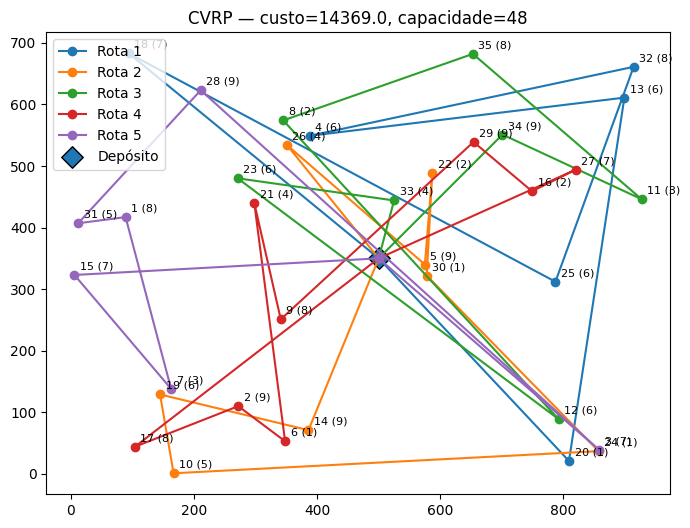

In [7]:
# Teste simples do decoder.
permutacao = list(range(1, instancia.n_clientes + 1))
random.Random(10).shuffle(permutacao)

solucao_split = split_capacitado(
    instancia,
    permutacao
)

print(solucao_split)
print("Viável?", solucao_split.viavel() if solucao_split else False)

if solucao_split:
    for k, rota in enumerate(solucao_split.rotas):
        print(
            f"Rota {k + 1}: carga={solucao_split.carga_rota(rota):2d} "
            f"/ {solucao_split.capacidade}"
        )

    plot_cvrp(solucao_split)


In [8]:
def avaliar_permutacao(I, permutacao, penalidade=1e12):
    S = split_capacitado(I, permutacao)

    if S is None:
        return penalidade

    return S.custo()


# 3. Algoritmo Genético implementado passo a passo

Um Algoritmo Genético trabalha com uma **população** de soluções.

No nosso caso, cada indivíduo é uma permutação:

$$
\pi=(\pi_1,\ldots,\pi_n).
$$

A qualidade do indivíduo é calculada por

$$
\pi
\longrightarrow
\operatorname{SplitCapacitado}(\pi)
\longrightarrow
f(\pi).
$$

A cada geração aplicaremos:

1. **avaliação**;
2. **elitismo**;
3. **seleção**;
4. **crossover**;
5. **mutação**.

Essa estrutura mantém a ideia central do caderno original, mas agora os operadores
evolutivos trabalham apenas sobre permutações.


## População inicial

A população inicial será formada por permutações aleatórias dos clientes.

Em aplicações reais, poderíamos misturar indivíduos aleatórios com soluções
construídas por heurísticas, mas começaremos com uma população totalmente aleatória
para observar melhor o efeito do processo evolutivo.


In [9]:
def populacao_inicial(I, tamanho_populacao, rng):
    base = list(range(1, I.n_clientes + 1))
    populacao = []

    for _ in range(tamanho_populacao):
        x = base.copy()
        rng.shuffle(x)
        populacao.append(x)

    return populacao


## Operador de crossover

Reaproveitaremos a ideia de **crossover de aresta alternada** do caderno original.

O cuidado fundamental é que um filho precisa continuar sendo uma permutação:
nenhum cliente pode aparecer duas vezes e nenhum cliente pode desaparecer.

Começamos por um cliente de um dos pais e, alternadamente, tentamos seguir a
ordem encontrada em cada progenitor, pulando clientes que já foram utilizados.


In [10]:
def cruzamento_aresta_alternada(mae1, mae2, rng):
    """
    Produz uma permutação filha alternando sucessores observados nos dois pais.
    """
    n = len(mae1)

    if set(mae1) != set(mae2):
        raise ValueError("Os pais devem representar o mesmo conjunto de clientes.")

    atual = rng.choice(mae1)
    filha = [atual]
    restantes = set(mae1)
    restantes.remove(atual)

    iteracao = 0

    while restantes:
        mae = mae1 if iteracao % 2 == 0 else mae2
        pos = mae.index(atual)

        escolhido = None

        for passo in range(1, n + 1):
            candidato = mae[(pos + passo) % n]

            if candidato in restantes:
                escolhido = candidato
                break

        # Em princípio sempre encontramos um candidato, mas mantemos fallback.
        if escolhido is None:
            escolhido = rng.choice(list(restantes))

        filha.append(escolhido)
        restantes.remove(escolhido)
        atual = escolhido
        iteracao += 1

    return filha


def cruzamento(mae1, mae2, rng):
    filha1 = cruzamento_aresta_alternada(mae1, mae2, rng)
    filha2 = cruzamento_aresta_alternada(mae2, mae1, rng)
    return filha1, filha2


## Operadores de mutação

Utilizaremos três movimentos já familiares:

- **swap**: troca duas posições;
- **relocate**: remove um cliente e o reinsere em outra posição;
- **inversão**: inverte um segmento da permutação.

Cada mutação escolhe aleatoriamente um dos três movimentos.


In [11]:
def mutacao(permutacao, rng):
    x = permutacao.copy()

    if len(x) < 2:
        return x

    operador = rng.randrange(3)
    i, j = sorted(rng.sample(range(len(x)), 2))

    if operador == 0:
        # swap
        x[i], x[j] = x[j], x[i]

    elif operador == 1:
        # relocate
        cliente = x.pop(j)
        x.insert(i, cliente)

    else:
        # inversão
        x[i:j + 1] = reversed(x[i:j + 1])

    return x


## Avaliação e seleção

A avaliação utiliza o mesmo `split_capacitado` para todos os indivíduos.

Manteremos também a ideia de **seleção por torneio com viés para a elite**:

- com probabilidade `vies`, um candidato do torneio é sorteado na elite;
- caso contrário, é sorteado na população inteira;
- vence o candidato de menor custo.


In [12]:
def avaliar_populacao(I, populacao, cache=None):
    if cache is None:
        cache = {}

    avaliados = []

    for perm in populacao:
        chave = tuple(perm)

        if chave not in cache:
            cache[chave] = avaliar_permutacao(I, perm)

        avaliados.append({
            "perm": perm,
            "custo": cache[chave]
        })

    avaliados.sort(key=lambda z: z["custo"])
    return avaliados


def torneio(avaliados, tamanho_elite, vies, rodadas, rng):
    melhor = None

    for _ in range(rodadas):
        if rng.random() < vies:
            candidato = rng.randrange(tamanho_elite)
        else:
            candidato = rng.randrange(len(avaliados))

        if (
            melhor is None
            or avaliados[candidato]["custo"] < avaliados[melhor]["custo"]
        ):
            melhor = candidato

    return avaliados[melhor]["perm"]


## Algoritmo Genético

A próxima geração é composta por três grupos:

1. **elite**: melhores indivíduos são copiados sem alteração;
2. **mutantes**: indivíduos selecionados sofrem mutação;
3. **descendentes**: novos indivíduos são produzidos por crossover.

O histórico registrará:

- melhor custo;
- custo médio;
- diversidade da população, medida pela proporção de permutações distintas.


In [13]:
def genetico_manual(
    I,
    tamanho_populacao=80,
    elite=0.20,
    vies=0.60,
    taxa_mutacao=0.20,
    rodadas=3,
    max_geracao=200,
    seed=1,
    verbose=False
):
    rng = random.Random(seed)

    tamanho_elite = max(
        1,
        round(tamanho_populacao * elite)
    )

    tamanho_mutacao = max(
        1,
        round(tamanho_populacao * taxa_mutacao)
    )

    if tamanho_elite + tamanho_mutacao >= tamanho_populacao:
        raise ValueError(
            "Elite + mutantes devem deixar espaço para descendentes."
        )

    populacao = populacao_inicial(
        I,
        tamanho_populacao,
        rng
    )

    cache = {}
    historico = []

    for geracao in range(max_geracao + 1):
        avaliados = avaliar_populacao(
            I,
            populacao,
            cache
        )

        custos = [z["custo"] for z in avaliados]
        finitos = [c for c in custos if c < 1e12]

        historico.append({
            "geracao": geracao,
            "melhor": custos[0],
            "media": statistics.mean(finitos) if finitos else 1e12,
            "diversidade": len({
                tuple(z["perm"]) for z in avaliados
            }) / len(avaliados)
        })

        if verbose and (
            geracao == 0
            or geracao % 20 == 0
            or geracao == max_geracao
        ):
            print(
                f"Geração {geracao:4d} | "
                f"melhor={custos[0]:9.2f} | "
                f"média={historico[-1]['media']:9.2f} | "
                f"diversidade={historico[-1]['diversidade']:.2f}"
            )

        if geracao == max_geracao:
            break

        proxima = [
            avaliados[i]["perm"].copy()
            for i in range(tamanho_elite)
        ]

        # Mutantes.
        for _ in range(tamanho_mutacao):
            pai = torneio(
                avaliados,
                tamanho_elite,
                vies,
                rodadas,
                rng
            )
            proxima.append(
                mutacao(pai, rng)
            )

        # Descendentes por crossover.
        while len(proxima) < tamanho_populacao:
            pai1 = torneio(
                avaliados,
                tamanho_elite,
                vies,
                rodadas,
                rng
            )
            pai2 = torneio(
                avaliados,
                tamanho_elite,
                vies,
                rodadas,
                rng
            )

            f1, f2 = cruzamento(
                pai1,
                pai2,
                rng
            )

            proxima.append(f1)

            if len(proxima) < tamanho_populacao:
                proxima.append(f2)

        populacao = proxima

    melhor_perm = avaliados[0]["perm"]
    melhor_solucao = split_capacitado(
        I,
        melhor_perm
    )

    return melhor_solucao, melhor_perm, pd.DataFrame(historico)


Geração    0 | melhor= 14839.07 | média= 16923.86 | diversidade=1.00
Geração   20 | melhor=  9116.45 | média= 10415.75 | diversidade=1.00
Geração   40 | melhor=  7860.10 | média=  8934.40 | diversidade=0.92
Geração   60 | melhor=  7385.05 | média=  8061.22 | diversidade=0.88
Geração   80 | melhor=  6451.60 | média=  7072.37 | diversidade=0.68
Geração  100 | melhor=  6266.73 | média=  7439.06 | diversidade=0.67
Geração  120 | melhor=  6266.73 | média=  6919.30 | diversidade=0.63

Melhor solução manual:
Clientes=35 | Veículos≤5 | Capacidade=48 | Rotas=5 | Custo=6266.73


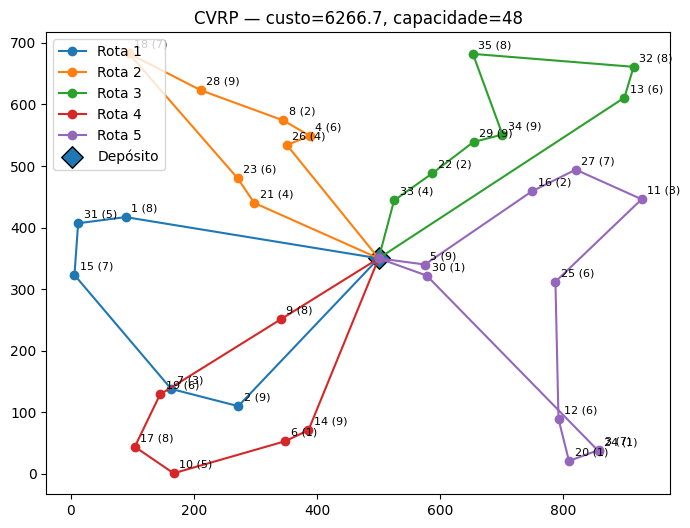

In [14]:
sol_manual, perm_manual, hist_manual = genetico_manual(
    instancia,
    tamanho_populacao=60,
    elite=0.20,
    vies=0.60,
    taxa_mutacao=0.20,
    rodadas=3,
    max_geracao=120,
    seed=7,
    verbose=True
)

print()
print("Melhor solução manual:")
print(sol_manual)

plot_cvrp(sol_manual)


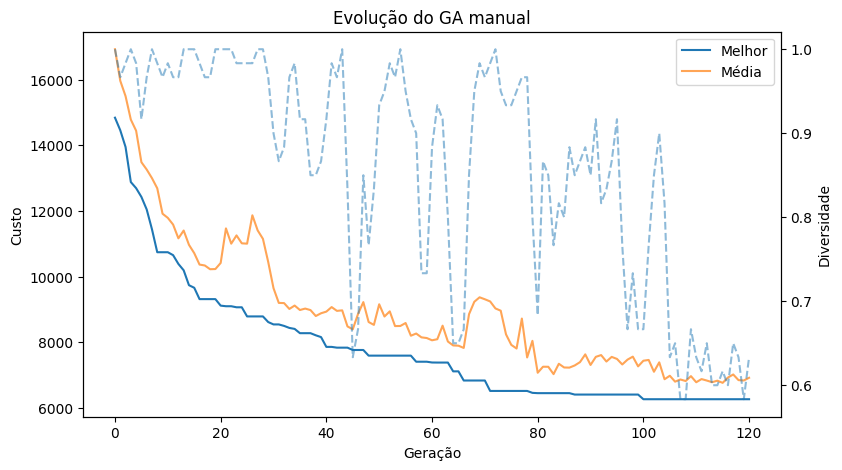

In [15]:
fig, ax1 = plt.subplots(figsize=(9, 5))

ax1.plot(
    hist_manual["geracao"],
    hist_manual["melhor"],
    label="Melhor"
)

ax1.plot(
    hist_manual["geracao"],
    hist_manual["media"],
    label="Média",
    alpha=0.7
)

ax1.set_xlabel("Geração")
ax1.set_ylabel("Custo")
ax1.legend(loc="upper right")

ax2 = ax1.twinx()
ax2.plot(
    hist_manual["geracao"],
    hist_manual["diversidade"],
    linestyle="--",
    alpha=0.5
)
ax2.set_ylabel("Diversidade")

plt.title("Evolução do GA manual")
plt.show()


# 4. Ajuste de parâmetros do GA manual

Como no caderno original, podemos estudar sistematicamente o efeito dos parâmetros.

Uma comparação adequada deve utilizar:

- a **mesma instância**;
- múltiplas sementes;
- a mesma configuração em todas as repetições.

Abaixo deixamos funções para automatizar os experimentos. A grade de demonstração
é propositalmente pequena para que o notebook continue executável em aula. Nos
exercícios ela poderá ser ampliada.


In [16]:
def rodar_config_manual(
    I,
    tam_pop,
    elite,
    vies,
    taxa_mut,
    rodadas,
    max_geracao,
    repeticoes=3,
    seed_inicial=0
):
    resultados = []

    for rep in range(repeticoes):
        sol, _, _ = genetico_manual(
            I,
            tamanho_populacao=tam_pop,
            elite=elite,
            vies=vies,
            taxa_mutacao=taxa_mut,
            rodadas=rodadas,
            max_geracao=max_geracao,
            seed=seed_inicial + rep,
            verbose=False
        )

        resultados.append(sol.custo())

    return {
        "tam_pop": tam_pop,
        "elite": elite,
        "vies": vies,
        "taxa_mutacao": taxa_mut,
        "rodadas": rodadas,
        "max_geracao": max_geracao,
        "media": statistics.mean(resultados),
        "desvio": statistics.stdev(resultados) if len(resultados) > 1 else 0.0,
        "melhor": min(resultados),
        "pior": max(resultados),
    }


In [17]:
# Demonstração curta.
# Para um estudo mais completo, amplie a grade no exercício correspondente.

configs_demo = [
    (40, 0.10, 0.60, 0.10),
    (40, 0.20, 0.60, 0.20),
    (60, 0.20, 0.60, 0.20),
    (60, 0.30, 0.60, 0.30),
]

resultados_demo = []

for tam_pop, elite, vies, taxa_mut in configs_demo:
    resultados_demo.append(
        rodar_config_manual(
            instancia,
            tam_pop=tam_pop,
            elite=elite,
            vies=vies,
            taxa_mut=taxa_mut,
            rodadas=3,
            max_geracao=60,
            repeticoes=3
        )
    )

df_tuning = pd.DataFrame(
    resultados_demo
).sort_values("media")

df_tuning


,tam_pop,elite,vies,taxa_mutacao,rodadas,max_geracao,media,desvio,melhor,pior
1,40,0.2,0.6,0.2,3,60,7433.986211,352.491517,7027.458845,7654.625015
2,60,0.2,0.6,0.2,3,60,7451.186970,146.269292,7296.593638,7587.393584
3,60,0.3,0.6,0.3,3,60,7747.140597,309.665759,7497.210478,8093.564646
0,40,0.1,0.6,0.1,3,60,8446.917246,682.626947,8023.600306,9234.406963


# 5. BRKGA com `pymoo`

Agora utilizaremos uma implementação **semi-automática**.

No **Biased Random-Key Genetic Algorithm (BRKGA)**, cada indivíduo é um vetor
de números reais em \([0,1]\):

$$
x=(x_1,x_2,\ldots,x_n).
$$

A permutação é obtida ordenando as chaves:

$$
\pi=\operatorname{argsort}(x).
$$

Por exemplo,

$$
x=(0.72,0.10,0.55,0.31)
$$

produz a ordem

$$
(2,4,3,1).
$$

Nosso decoder será, portanto,

$$
\boxed{
\text{random keys}
\rightarrow
\text{argsort}
\rightarrow
\text{permutação}
\rightarrow
\text{Split capacitado}
\rightarrow
\text{custo}
}
$$

A biblioteca `pymoo` cuida de:

- população de random keys;
- separação entre elite e não elite;
- cruzamento enviesado;
- geração de mutantes;
- evolução da população.

Nós ainda precisamos fornecer a **interpretação do cromossomo** e a **função objetivo**.

> A seção abaixo foi escrita para a API do `pymoo` 0.6.2.


In [18]:
# Em Google Colab, execute esta célula uma vez.
%pip -q install pymoo==0.6.2


     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 72.7/72.7 kB 3.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.2/5.2 MB 62.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 347.2/347.2 kB 26.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 879.5/879.5 kB 49.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 78.4/78.4 kB 6.4 MB/s eta 0:00:00


In [19]:
from pymoo.algorithms.soo.nonconvex.brkga import BRKGA
from pymoo.core.callback import Callback
from pymoo.core.duplicate import ElementwiseDuplicateElimination
from pymoo.core.problem import ElementwiseProblem
from pymoo.optimize import minimize


## Definindo o problema para o `pymoo`

Cada variável é uma chave real no intervalo

$$
0\leq x_i\leq1.
$$

O `argsort` transforma as chaves em uma permutação.

Como vetores de chaves diferentes podem produzir a mesma permutação, vamos armazenar
um `hash` do **fenótipo** para que a eliminação de duplicatas considere a solução
combinatória, e não os valores reais das chaves.


In [20]:
class CVRPBRKGA(ElementwiseProblem):
    def __init__(self, instancia, penalidade=1e12):
        self.instancia = instancia
        self.penalidade = penalidade

        super().__init__(
            n_var=instancia.n_clientes,
            n_obj=1,
            n_ieq_constr=0,
            xl=0.0,
            xu=1.0
        )

    def _evaluate(self, x, out, *args, **kwargs):
        # argsort gera índices 0,...,n-1.
        # Somamos 1 porque os clientes do CVRP são 1,...,n.
        permutacao = (
            np.argsort(x) + 1
        ).astype(int)

        S = split_capacitado(
            self.instancia,
            permutacao
        )

        if S is None:
            custo = self.penalidade
        else:
            custo = S.custo()

        out["F"] = float(custo)
        out["pheno"] = permutacao
        out["hash"] = hash(tuple(permutacao.tolist()))


class PermutationDuplicateElimination(
    ElementwiseDuplicateElimination
):
    def is_equal(self, a, b):
        return a.get("hash") == b.get("hash")


## Registrando a evolução

Usaremos um `Callback` para guardar apenas as informações necessárias a cada geração:

- melhor valor da população;
- valor médio;
- número acumulado de avaliações.

Isso evita armazenar uma cópia completa do algoritmo em todas as gerações.


In [21]:
class HistoricoBRKGA(Callback):
    def __init__(self):
        super().__init__()
        self.data["melhor"] = []
        self.data["media"] = []
        self.data["avaliacoes"] = []

    def notify(self, algorithm):
        F = algorithm.pop.get("F").reshape(-1)

        self.data["melhor"].append(
            float(np.min(F))
        )

        self.data["media"].append(
            float(np.mean(F))
        )

        self.data["avaliacoes"].append(
            int(algorithm.evaluator.n_eval)
        )


## Executando o BRKGA

Os principais parâmetros são:

- `n_elites`: quantidade de indivíduos elite;
- `n_offsprings`: quantidade de descendentes gerados por cruzamento;
- `n_mutants`: quantidade de novos indivíduos aleatórios por geração;
- `bias`: probabilidade de um alelo do filho ser herdado do pai elite.

A população total é formada aproximadamente por

$$
n_{\text{elites}}+
n_{\text{offsprings}}+
n_{\text{mutants}}.
$$

A configuração abaixo produz uma população de 60 indivíduos, comparável ao
exemplo do GA manual.


Melhor custo BRKGA = 6815.763525594701
Avaliações = 5772


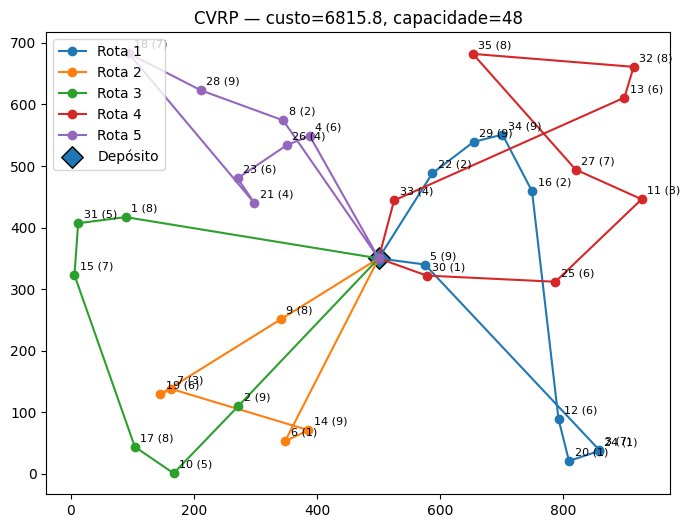

In [22]:
problema_brkga = CVRPBRKGA(
    instancia
)

algoritmo_brkga = BRKGA(
    n_elites=12,
    n_offsprings=42,
    n_mutants=6,
    bias=0.70,
    eliminate_duplicates=PermutationDuplicateElimination()
)

callback_brkga = HistoricoBRKGA()

resultado_brkga = minimize(
    problema_brkga,
    algoritmo_brkga,
    ("n_gen", 120),
    seed=7,
    callback=callback_brkga,
    verbose=False
)

permutacao_brkga = (
    np.argsort(resultado_brkga.X) + 1
).astype(int).tolist()

sol_brkga = split_capacitado(
    instancia,
    permutacao_brkga
)

print("Melhor custo BRKGA =", sol_brkga.custo())
print(
    "Avaliações =",
    resultado_brkga.algorithm.evaluator.n_eval
)

plot_cvrp(sol_brkga)


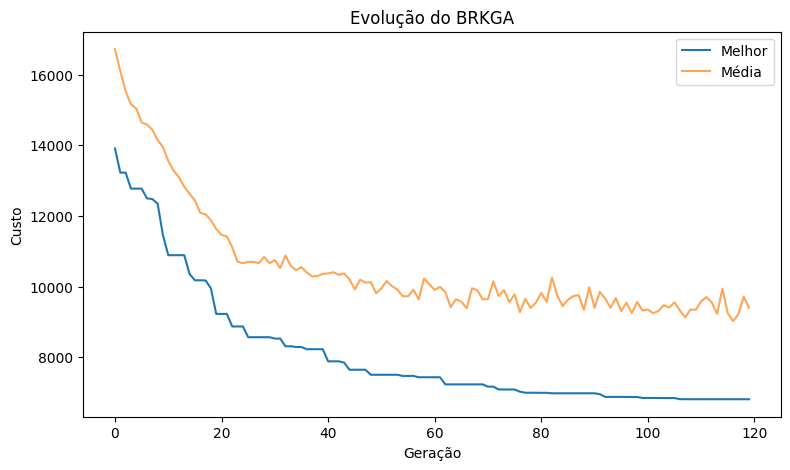

In [23]:
hist_brkga = pd.DataFrame({
    "geracao": range(
        len(resultado_brkga.algorithm.callback.data["melhor"])
    ),
    "melhor": resultado_brkga.algorithm.callback.data["melhor"],
    "media": resultado_brkga.algorithm.callback.data["media"],
    "avaliacoes": resultado_brkga.algorithm.callback.data["avaliacoes"],
})

plt.figure(figsize=(9, 5))

plt.plot(
    hist_brkga["geracao"],
    hist_brkga["melhor"],
    label="Melhor"
)

plt.plot(
    hist_brkga["geracao"],
    hist_brkga["media"],
    label="Média",
    alpha=0.7
)

plt.xlabel("Geração")
plt.ylabel("Custo")
plt.title("Evolução do BRKGA")
plt.legend()
plt.show()


# 6. Comparando GA manual e BRKGA

Os dois algoritmos utilizam exatamente o mesmo problema e exatamente o mesmo decoder:

$$
\operatorname{SplitCapacitado}.
$$

A diferença está em como exploram o espaço de permutações.

### GA manual

$$
\text{permutação}
\rightarrow
\text{crossover específico}
\rightarrow
\text{mutação específica}.
$$

### BRKGA

$$
\text{random keys}
\rightarrow
\text{crossover enviesado em variáveis reais}
\rightarrow
\text{argsort}.
$$

Isso permite discutir uma questão central em metaheurísticas:

> Quanto do desempenho vem do algoritmo evolutivo e quanto vem da representação e
> do decoder?

Uma comparação rigorosa deve usar múltiplas sementes e, idealmente, controlar
também o número de avaliações ou o tempo de execução.


In [24]:
print("GA manual :", sol_manual.custo())
print("BRKGA     :", sol_brkga.custo())

comparacao = pd.DataFrame({
    "algoritmo": ["GA manual", "BRKGA"],
    "melhor_custo": [
        sol_manual.custo(),
        sol_brkga.custo()
    ]
})

comparacao


GA manual : 6266.730789063127
BRKGA     : 6815.763525594701


,algoritmo,melhor_custo
0,GA manual,6266.730789
1,BRKGA,6815.763526


## Síntese

Neste notebook apareceram dois níveis de generalidade.

### O problema fornece

- clientes;
- demandas;
- capacidade;
- custos de viagem;
- decoder `split_capacitado`.

### O algoritmo evolutivo fornece

- população;
- seleção;
- recombinação;
- diversidade;
- mecanismo de evolução.

No GA manual, precisamos construir explicitamente operadores adequados para
permutações.

No BRKGA, a evolução acontece em vetores reais e o principal componente específico
do problema é o decoder:

$$
\boxed{
\text{chaves reais}
\rightarrow
\text{permutação}
\rightarrow
\text{Split capacitado}
}.
$$

Essa separação entre **mecanismo evolutivo genérico** e **decoder específico do
problema** será útil em muitos outros problemas de otimização combinatória.


# Exercícios

Os três primeiros exercícios formam a lista regular. Os exercícios 4 e 5 são
adicionais para a pós-graduação.


## Exercício 1 — Evolução da população

A implementação do GA manual já registra:

- melhor custo de cada geração;
- custo médio;
- diversidade da população.

Realize experimentos com diferentes instâncias e analise esses três indicadores.

### Atividades

1. Produza gráficos mostrando, ao longo das gerações:
   - melhor custo;
   - custo médio;
   - diversidade.

2. Identifique períodos de:
   - melhoria rápida;
   - estabilização;
   - perda de diversidade.

3. Execute o algoritmo pelo menos 5 vezes para a mesma instância, utilizando
   sementes diferentes.

### Discussão

- O melhor indivíduo converge antes da média da população?
- A perda de diversidade coincide com a estabilização do custo?
- Todas as execuções convergem para soluções semelhantes?
- É possível observar indícios de convergência prematura?


## Exercício 2 — Exploração sistemática de parâmetros

Estude o efeito dos parâmetros do GA manual.

Monte uma grade contendo pelo menos:

$$
N\in\{30,50,80\}
$$

para o tamanho da população,

$$
p_e\in\{0.1,0.2,0.3\}
$$

para a proporção de elite, e

$$
p_m\in\{0.1,0.3,0.5\}
$$

para a proporção de mutantes.

Para cada configuração, realize pelo menos 5 execuções.

Registre:

- média;
- desvio-padrão;
- melhor resultado;
- pior resultado;
- tempo médio.

### Análise

1. Apresente as cinco melhores configurações segundo o resultado médio.
2. Construa gráficos mostrando o efeito dos principais parâmetros.
3. Compare uma configuração boa e uma configuração ruim.
4. Discuta a diferença entre:
   - melhor resultado isolado;
   - qualidade média;
   - estabilidade.
5. Você consegue eleger uma única "melhor configuração"? Argumente.


## Exercício 3 — GA manual versus BRKGA

Compare:

1. o GA implementado passo a passo;
2. o BRKGA do `pymoo`.

Utilize:

- as mesmas instâncias;
- o mesmo `split_capacitado`;
- pelo menos 10 sementes para cada método.

Procure utilizar um esforço computacional comparável. Você pode escolher:

- mesmo número aproximado de avaliações; ou
- mesmo limite de tempo.

Registre:

- média;
- desvio-padrão;
- melhor;
- pior;
- tempo;
- número de avaliações.

### Discussão

1. Qual método apresenta melhor qualidade média?
2. Qual apresenta menor variabilidade?
3. Qual converge mais rapidamente?
4. Em qual método foi necessário escrever mais código específico do problema?
5. O que permaneceu idêntico nas duas abordagens?
6. A representação e o decoder parecem ser tão importantes quanto o próprio
   mecanismo evolutivo?


# Exercícios adicionais — Pós-graduação

## Exercício 4 — Novo crossover e estudo de ablação

O GA manual utiliza o crossover de aresta alternada reaproveitado do caderno original.

Implemente um segundo operador adequado para permutações, por exemplo:

- **Order Crossover (OX)**;
- **Partially Mapped Crossover (PMX)**;
- **Edge Recombination (ERX)**.

Compare três versões:

$$
GA_{\text{original}},
\qquad
GA_{\text{novo crossover}},
\qquad
GA_{\text{sem crossover}}.
$$

Na versão sem crossover, complete a população apenas com elitismo e mutação.

Use as mesmas instâncias, sementes e orçamento de avaliações.

### Questões

1. O novo crossover melhora o resultado médio?
2. Algum crossover preserva melhor a diversidade?
3. O GA sem crossover perde qualidade?
4. Qual é a contribuição efetiva do crossover para o processo evolutivo?

Apresente suas conclusões com base em múltiplas execuções, e não apenas no melhor
resultado observado.


## Exercício 5 — Algoritmo Genético Memético

Construa uma versão híbrida do GA manual acrescentando uma pequena **busca local**
a alguns indivíduos.

Por exemplo, após gerar um descendente:

1. aplique o Split para avaliar sua permutação;
2. gere vizinhos utilizando `swap`, `relocate` ou inversão;
3. aceite movimentos de melhoria;
4. limite a busca local a um pequeno número de tentativas.

Não é necessário aplicar busca local a toda a população. Experimente, por exemplo:

- somente no melhor descendente da geração;
- nos 10% melhores descendentes;
- em um indivíduo escolhido aleatoriamente.

Compare:

$$
GA
\qquad\text{versus}\qquad
GA+\text{busca local}.
$$

### Discussão

1. A busca local melhora a qualidade final?
2. O ganho compensa o aumento no tempo de execução?
3. Aplicar busca local em muitos indivíduos reduz a diversidade?
4. Existe um ponto de equilíbrio entre exploração global e intensificação local?

Essa combinação de algoritmo populacional com busca local é frequentemente chamada
de **algoritmo memético**.


## Referências e documentação

- Prins, C. (2004). *A simple and effective evolutionary algorithm for the vehicle routing problem*. Computers & Operations Research, 31(12), 1985–2002.
- Prins, C., Lacomme, P., & Prodhon, C. (2014). *Order-first split-second methods for vehicle routing problems: A review*. Transportation Research Part C, 40, 179–200.
- Vidal, T. (2016). *Split algorithm in O(n) for the capacitated vehicle routing problem*. Computers & Operations Research, 69, 40–47.
- `pymoo` BRKGA documentation: https://pymoo.org/algorithms/soo/brkga.html
- `pymoo` callback documentation: https://pymoo.org/interface/callback.html
